# 08 - Final Comparison: Bagging vs Boosting vs Stacking

## 1. Objective

The three ensemble types were trained, tuned and tested **separately**:

| Notebook | Ensemble type | Model | Settings (chosen on 2023) |
|---|---|---|---|
| 05 | **Bagging** | Random Forest | 200 trees, `min_samples_leaf = 10` |
| 06 | **Boosting** | XGBoost | 400 rounds, `max_depth = 2`, `learning_rate = 0.05` |
| 07 | **Stacking** | Random Forest + XGBoost + Linear Regression | Linear Regression meta-model with `positive=True` |

This notebook answers the main question of the project, **how do bagging, boosting and stacking compare on unseen Sri Lankan dengue data?** It:
1. Loads the **final models saved in notebooks 05, 06 and 07** (all trained on target weeks 2007-2023). Nothing is trained or tuned here.
2. Scores **Random Forest, XGBoost, Stacking and persistence on the identical test rows** (target weeks 2024-2026).
3. Investigates **why the ensembles differ**: by year, by district, at outbreak peaks, and why stacking did or did not beat the Random Forest.
4. Saves the comparison results and all test predictions for the dashboard.

**Rules that keep the test fair**
- All settings were fixed in notebooks 05-07 using only the 2023 validation year (and, for stacking, walk-forward predictions up to 2023). Nothing is tuned or changed here after looking at the test scores.
- The test set and the leakage check are the same as in notebooks 05-07.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from xgboost import XGBRegressor

TRAIN_PATH = Path("../dataset/processed/train.csv")
TEST_PATH = Path("../dataset/processed/test.csv")
CLEANED_PATH = Path("../dataset/processed/02_cleaned_weekly_data.csv")

# saved in notebook 05 (bagging), 06 (boosting) and 07 (stacking)
RF_RESULTS_PATH = Path("../models/05_random_forest_results.json")
RF_MODEL_PATH = Path("../models/05_final_random_forest_model.joblib")
XGB_RESULTS_PATH = Path("../models/06_xgboost_results.json")
XGB_MODEL_PATH = Path("../models/06_final_xgboost_model.json")
STACK_RESULTS_PATH = Path("../models/07_stacking_results.json")
LR_MODEL_PATH = Path("../models/07_final_linear_regression_model.joblib")
META_MODEL_PATH = Path("../models/07_stacking_meta_model.joblib")

# saved by this notebook
RESULTS_PATH = Path("../models/08_final_test_results.json")
PREDICTIONS_PATH = Path("../models/08_test_predictions.csv")

rf_info = json.loads(RF_RESULTS_PATH.read_text())
xgb_info = json.loads(XGB_RESULTS_PATH.read_text())
stack_info = json.loads(STACK_RESULTS_PATH.read_text())

# all ensembles must use the same features, target, seed and validation year
for key in ["features", "target", "random_state", "validation_year"]:
    assert rf_info[key] == xgb_info[key] == stack_info[key], key
FEATURES = rf_info["features"]
TARGET = rf_info["target"]
RANDOM_STATE = rf_info["random_state"]
RF_PARAMS = rf_info["params"]
XGB_PARAMS = xgb_info["params"]
BASE_MODELS = stack_info["base_models"]   # column order the meta-model expects
print("Random Forest settings:", RF_PARAMS)
print("XGBoost settings:      ", XGB_PARAMS)
print("Stacking:              ", stack_info["meta_model"], "on", BASE_MODELS)

MODELS = ["Persistence", "Random Forest", "XGBoost", "Stacking"]
ENSEMBLES = ["Random Forest", "XGBoost", "Stacking"]

# chart colours (the same as notebooks 04-07)
COLORS = {"Persistence": "#898781", "Random Forest": "#2a78d6", "XGBoost": "#1baf7a",
          "Linear Regression": "#8f6bb3", "Stacking": "#d6457f"}
INK, GRID = "#0b0b0b", "#e4e3df"

Random Forest settings: {'n_estimators': 200, 'min_samples_leaf': 10}
XGBoost settings:       {'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.05}
Stacking:               Linear Regression meta-model (positive=True) on ['Random Forest', 'XGBoost', 'Linear Regression']


## 2. Load the data (same steps as notebooks 05-07)

- `train.csv`: target weeks 2007-2023 (used here only for the diagnostics in section 5.4). `test.csv`: target weeks 2024-2026.
- **Leakage check:** rows whose current week (`is_imputed`) or target week (`target_imputed`) was interpolated in notebook 02 are removed. An interpolated value was calculated from the following week, i.e. from the answer.
- The test set must contain exactly the same number of rows as in notebooks 05-07, so all models are scored on the same observations.

In [2]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])
test = pd.read_csv(TEST_PATH, parse_dates=["start_date", "target_date"])

train_leaky = train["is_imputed"] | train["target_imputed"]
test_leaky = test["is_imputed"] | test["target_imputed"]
train = train[~train_leaky].reset_index(drop=True)
test = test[~test_leaky].reset_index(drop=True)
print("removed interpolated rows: train", train_leaky.sum(), "| test", test_leaky.sum())

# safety checks
assert train["target_date"].max() < test["target_date"].min()          # all training weeks come first
assert train[FEATURES + [TARGET]].notna().all().all() and test[FEATURES + [TARGET]].notna().all().all()
assert TARGET not in FEATURES and "target_log_next" not in FEATURES     # the answer is not an input
assert (test["target_date"] - test["start_date"] == pd.Timedelta(days=7)).all()  # target = the following week
assert len(test) == rf_info["test_rows"] == xgb_info["test_rows"] == stack_info["test_rows"]  # same test rows as notebooks 05-07
assert len(train) == rf_info["final_train_rows"] == xgb_info["final_train_rows"]

X_test, y_test = test[FEATURES], test[TARGET].to_numpy()

print("training rows:", len(train), "| target weeks", train["target_date"].min().date(), "to", train["target_date"].max().date())
print("test rows:    ", len(test), "| target weeks", test["target_date"].min().date(), "to", test["target_date"].max().date())

removed interpolated rows: train 52 | test 106
training rows: 21684 | target weeks 2007-12-29 to 2023-12-30
test rows:     3508 | target weeks 2024-01-06 to 2026-08-29


## 3. Load the final models and predict the test weeks

- **Random Forest** (notebook 05): the average of 200 trees. Each leaf holds real past counts, so it cannot predict below 0 (or above the largest training value). It was saved with `n_jobs=1`, so its predictions are exactly repeatable.
- **XGBoost** (notebook 06): clipped at 0, as in notebook 06, because boosting adds up corrections and can go negative.
- **Stacking** (notebook 07): the three base predictions (Random Forest, XGBoost clipped at 0, Linear Regression), in this order, go into the saved meta-model; its output is clipped at 0.
- **Persistence:** next week = this week (`current_week_cases`).

As a check, the loaded models must give exactly the test scores recorded in notebooks 05, 06 and 07.

**Only load joblib/pickle files from a trusted source** - loading one can run code.

In [3]:
final_rf = joblib.load(RF_MODEL_PATH)
final_xgb = XGBRegressor()
final_xgb.load_model(XGB_MODEL_PATH)
final_lr = joblib.load(LR_MODEL_PATH)
meta_model = joblib.load(META_MODEL_PATH)


def base_predictions(X):
    """The stack's three base predictions, in the column order used in notebook 07."""
    return pd.DataFrame({
        "Random Forest": final_rf.predict(X),
        "XGBoost": np.clip(final_xgb.predict(X), 0, None),
        "Linear Regression": final_lr.predict(X),
    }, index=X.index)[BASE_MODELS]


def predict_with(name, X):
    if name == "Random Forest":
        return final_rf.predict(X)
    if name == "XGBoost":
        return np.clip(final_xgb.predict(X), 0, None)
    return np.clip(meta_model.predict(base_predictions(X)), 0, None)   # Stacking


predictions = {"Persistence": test["current_week_cases"].to_numpy(dtype=float)}
for name in ENSEMBLES:
    predictions[name] = predict_with(name, X_test)

# all models predict exactly the same test rows
assert all(len(p) == len(test) for p in predictions.values())
assert (predictions["Random Forest"] >= 0).all()

# the loaded models must reproduce the test scores of notebooks 05, 06 and 07
for name, info in [("Random Forest", rf_info), ("XGBoost", xgb_info), ("Stacking", stack_info)]:
    mae_now = mean_absolute_error(y_test, predictions[name])
    print(f"{name:14s} test MAE now: {mae_now:.3f} | recorded: {info['test_scores'][name]['MAE']}")
    assert abs(mae_now - info["test_scores"][name]["MAE"]) < 0.0005

Random Forest  test MAE now: 12.529 | recorded: 12.529
XGBoost        test MAE now: 13.215 | recorded: 13.215
Stacking       test MAE now: 12.180 | recorded: 12.18


## 4. Final test results (2024-2026)

MAE and RMSE are in cases per district-week (lower is better). The last two columns show the change compared with persistence: **negative = smaller error than persistence**.

In [4]:
def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}


def score_table(rows):
    """MAE and RMSE of every model on the selected test rows, plus the change vs persistence."""
    table = pd.DataFrame({name: evaluate(y_test[rows], predictions[name][rows]) for name in MODELS}).T
    table["MAE vs persistence (%)"] = 100 * (table["MAE"] / table.loc["Persistence", "MAE"] - 1)
    table["RMSE vs persistence (%)"] = 100 * (table["RMSE"] / table.loc["Persistence", "RMSE"] - 1)
    return table


all_rows = np.ones(len(test), dtype=bool)
test_results = score_table(all_rows)
test_results.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.63,29.93,0.00,0.00
Random Forest,12.53,33.63,-0.80,12.37
XGBoost,13.22,39.19,4.63,30.94
Stacking,12.18,27.72,-3.56,-7.39


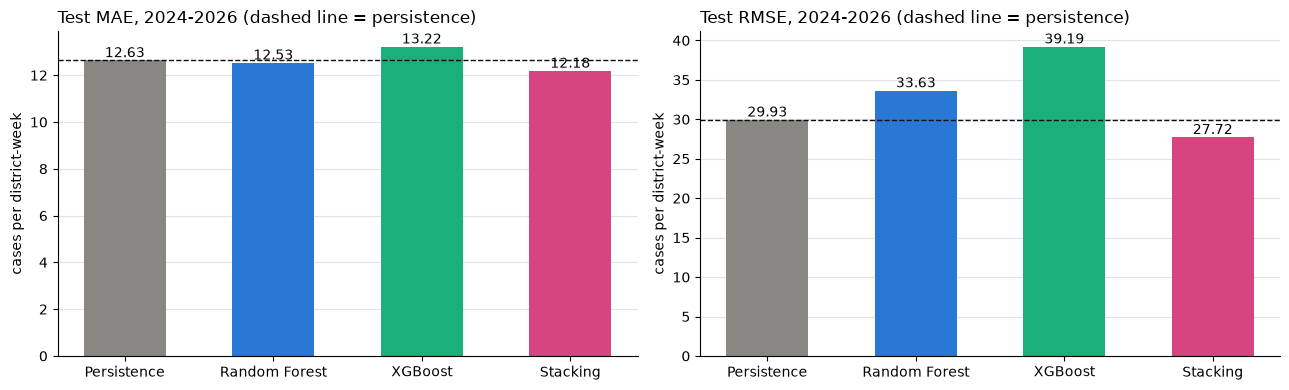

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = test_results[metric].to_numpy()
    ax.bar(MODELS, values, color=[COLORS[name] for name in MODELS], width=0.55)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.axhline(test_results.loc["Persistence", metric], color=INK, linewidth=1, linestyle="--")
    ax.set_title(f"Test {metric}, 2024-2026 (dashed line = persistence)", loc="left")
    ax.set_ylabel("cases per district-week")
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the test results show**

- **Stacking has the lowest test MAE and RMSE of the three ensembles:** MAE 12.18 (**-3.6%** vs persistence) and RMSE 27.72 (**-7.4%**). It is the only ensemble that beats persistence on **both** metrics.
- **Random Forest** has a slightly lower MAE than persistence (12.53, **-0.8%**) but a higher RMSE (33.63, **+12.4%**). **XGBoost** is worse than persistence on both (13.22, **+4.6%**; 39.19, **+30.9%**).
- **Bagging vs boosting:** the Random Forest beats XGBoost on both metrics. On the 2023 validation year the order was the other way round (XGBoost 18.10 vs Random Forest 18.14 MAE), but that gap was tiny.
- RMSE punishes large misses, so the big differences in RMSE come from a few outbreak weeks (section 5.3). Stacking's advantage is mainly that it makes fewer very large errors.

### Validation (2023) vs test (2024-2026)

The 2023 validation scores from notebooks 05-07 next to the new test scores. The test period includes the very large 2026 outbreak, so the fair comparison between periods is the **change vs persistence**, not the raw error.

In [6]:
# validation scores recorded in notebooks 05 (Random Forest), 06 (XGBoost) and 07 (Stacking)
valid_scores = {**rf_info["validation_scores"], **xgb_info["validation_scores"], **stack_info["validation_scores"]}
valid_table = pd.DataFrame(valid_scores).T.loc[MODELS]

period_comparison = pd.DataFrame({
    "validation MAE (2023)": valid_table["MAE"],
    "validation MAE vs persistence (%)": 100 * (valid_table["MAE"] / valid_table.loc["Persistence", "MAE"] - 1),
    "test MAE (2024-26)": test_results["MAE"],
    "test MAE vs persistence (%)": test_results["MAE vs persistence (%)"],
    "validation RMSE (2023)": valid_table["RMSE"],
    "test RMSE (2024-26)": test_results["RMSE"],
})
period_comparison.round(2)

,validation MAE (2023),validation MAE vs persistence (%),test MAE (2024-26),test MAE vs persistence (%),validation RMSE (2023),test RMSE (2024-26)
Persistence,18.17,0.00,12.63,0.00,41.82,29.93
Random Forest,18.14,-0.17,12.53,-0.80,42.32,33.63
XGBoost,18.10,-0.39,13.22,4.63,41.34,39.19
Stacking,18.11,-0.31,12.18,-3.56,40.83,27.72


On 2023 all four models were within 0.4% of each other in MAE. On the test years the differences are larger and the ranking changed: Stacking first, then Random Forest, persistence and XGBoost, while XGBoost had been (very narrowly) the best on 2023. **A model should not be called the best because it won a close validation comparison on one year.** This is the reason for keeping an untouched test set.

## 5. Why do the models differ? Diagnostics

### 5.1 Results by test year

In [7]:
test_year = test["target_date"].dt.year.to_numpy()
year_rows = []
for year in sorted(np.unique(test_year)):
    rows = test_year == year
    row = {"year": int(year), "rows": int(rows.sum()), "mean weekly cases": y_test[rows].mean()}
    for name in MODELS:
        row[f"{name} MAE"] = mean_absolute_error(y_test[rows], predictions[name][rows])
    for name in MODELS:
        row[f"{name} RMSE"] = root_mean_squared_error(y_test[rows], predictions[name][rows])
    year_rows.append(row)

by_year = pd.DataFrame(year_rows).set_index("year")
by_year.round(2)

,rows,mean weekly cases,Persistence MAE,Random Forest MAE,XGBoost MAE,Stacking MAE,Persistence RMSE,Random Forest RMSE,XGBoost RMSE,Stacking RMSE
year,,,,,,,,,,
2024,1352,37.14,10.45,9.53,9.47,10.24,21.15,18.73,20.62,19.65
2025,1352,37.57,8.68,8.31,8.27,8.63,15.20,15.05,14.77,14.78
2026,804,98.86,22.93,24.66,27.82,21.42,52.61,62.96,74.97,48.32


- **2024 and 2025** (moderate years, about 37 cases per district-week): **all three ensembles beat persistence** in MAE. Here the **tree ensembles are best** (2024: XGBoost 9.47, Random Forest 9.53; 2025: XGBoost 8.27, Random Forest 8.31). Stacking is a little behind (10.24 and 8.63), but still better than persistence.
- **2026** (very large outbreak, about 99 cases per district-week, data until August): the Random Forest (24.66, about +8%) and XGBoost (27.82, about +21%) are **worse** than persistence (22.93). **Stacking is the only ensemble that beats persistence in 2026** (MAE 21.42, RMSE 48.32 vs 52.61). XGBoost's 2026 RMSE (74.97) is much higher than everyone else's.

So the overall ranking is decided by **2026**: the tree ensembles are best in normal years, stacking is best in the outbreak year.

### 5.2 Results by district

MAE per district (the 26 reporting areas), sorted by the average number of cases. `best` is the model with the lowest MAE in that district.

In [8]:
district_rows = []
for district in sorted(test["district"].unique()):
    rows = (test["district"] == district).to_numpy()
    row = {"district": district, "mean weekly cases": y_test[rows].mean()}
    for name in MODELS:
        row[name] = mean_absolute_error(y_test[rows], predictions[name][rows])
    district_rows.append(row)

by_district = pd.DataFrame(district_rows).set_index("district").sort_values("mean weekly cases", ascending=False)
by_district["best"] = by_district[MODELS].idxmin(axis=1)
by_district.round(2)

,mean weekly cases,Persistence,Random Forest,XGBoost,Stacking,best
district,,,,,,
Colombo,305.26,49.43,54.14,58.12,44.89,Stacking
Gampaha,205.55,38.54,41.82,41.55,36.01,Stacking
Kandy,108.41,24.35,23.44,27.04,21.79,Stacking
Kalutara,89.58,22.36,23.35,29.56,22.54,Persistence
Ratnapura,88.53,19.96,19.35,17.97,19.15,XGBoost
Galle,68.19,16.05,14.37,16.48,15.52,Random Forest
Matara,64.40,18.55,17.08,19.10,17.55,Random Forest
Jaffna,56.29,16.52,14.31,15.22,15.36,Random Forest
Kurunegala,45.71,12.72,12.21,12.39,12.74,Random Forest


In [9]:
print("districts where each model has the lowest MAE:")
print(by_district["best"].value_counts().to_string())
print()
for name in ENSEMBLES:
    print(f"{name:14s} beats persistence in", (by_district[name] < by_district["Persistence"]).sum(), "of 26 districts")
print("Random Forest beats XGBoost in    ", (by_district["Random Forest"] < by_district["XGBoost"]).sum(), "of 26 districts")
print("Stacking beats Random Forest in   ", (by_district["Stacking"] < by_district["Random Forest"]).sum(), "of 26 districts")

districts where each model has the lowest MAE:
best
Random Forest    13
XGBoost           5
Stacking          4
Persistence       4

Random Forest  beats persistence in 19 of 26 districts
XGBoost        beats persistence in 16 of 26 districts
Stacking       beats persistence in 13 of 26 districts
Random Forest beats XGBoost in     18 of 26 districts
Stacking beats Random Forest in    7 of 26 districts


- By MAE, the **Random Forest is the best model in 13 of the 26 reporting areas**, XGBoost in 5, Stacking in 4 and persistence in 4. The Random Forest beats persistence in 19 areas, XGBoost in 16 and Stacking in only 13.
- But **Stacking is best in the three largest districts** (Colombo 44.89, Gampaha 36.01, Kandy 21.79), where the 2026 outbreak was largest. In Colombo and Gampaha, both tree ensembles were worse than persistence. Because the MAE is an average over all district-weeks, these big districts have a large effect on the overall score.
- So Stacking wins overall by doing much better in a few large districts, while the Random Forest is better in most small and medium ones (Stacking beats the Random Forest in only 7 of 26 areas).

### 5.3 Outbreak peaks: do the models overestimate?

The very high weeks are split by what happened next:
- **current week > 500, next week higher:** the outbreak is still growing.
- **current week > 500, next week lower or equal:** the peak has been reached or passed.

*Mean error* = average of (predicted - actual). **Positive = the model predicts too many cases.**

In [10]:
current = test["current_week_cases"].to_numpy()
high = current > 500
rising = y_test > current

groups = {
    "current week > 500, next week higher": high & rising,
    "current week > 500, next week lower or equal": high & ~rising,
    "all other weeks (current week <= 500)": ~high,
}

peak_rows = []
for label, rows in groups.items():
    row = {"group": label, "district-weeks": int(rows.sum())}
    for name in MODELS:
        row[f"{name} mean error"] = (predictions[name][rows] - y_test[rows]).mean()
    for name in MODELS:
        row[f"{name} MAE"] = mean_absolute_error(y_test[rows], predictions[name][rows])
    peak_rows.append(row)

peaks = pd.DataFrame(peak_rows).set_index("group")
peaks.round(1)

,district-weeks,Persistence mean error,Random Forest mean error,XGBoost mean error,Stacking mean error,Persistence MAE,Random Forest MAE,XGBoost MAE,Stacking MAE
group,,,,,,,,,
"current week > 500, next week higher",9,-191.9,-33.9,-201.3,-165.2,191.9,184.2,217.4,168.4
"current week > 500, next week lower or equal",28,161.8,197.1,237.5,136.5,161.8,211.8,262.1,136.8
all other weeks (current week <= 500),3471,0.6,0.6,0.8,1.5,11.0,10.5,10.7,10.8


In [11]:
share = {}
for name in MODELS:
    squared_error = (predictions[name] - y_test) ** 2
    share[name] = 100 * squared_error[high].sum() / squared_error.sum()

print(f"{high.sum()} district-weeks with more than 500 cases ({100 * high.mean():.1f}% of test rows)")
print("share of each model's total squared error that comes from these weeks:")
for name, value in share.items():
    print(f"  {name:14s} {value:.1f}%")

37 district-weeks with more than 500 cases (1.1% of test rows)
share of each model's total squared error that comes from these weeks:
  Persistence    50.4%
  Random Forest  62.8%
  XGBoost        67.7%
  Stacking       47.0%


The 10 largest XGBoost errors, with the Random Forest and Stacking predictions for the same week:

In [12]:
largest = test[["district", "start_date", "current_week_cases", TARGET]].copy()
largest["Random Forest"] = predictions["Random Forest"].round()
largest["XGBoost"] = predictions["XGBoost"].round()
largest["Stacking"] = predictions["Stacking"].round()
largest["XGBoost error"] = (predictions["XGBoost"] - y_test).round()
largest.reindex(largest["XGBoost error"].abs().sort_values(ascending=False).index).head(10)

,district,start_date,current_week_cases,cases_next,Random Forest,XGBoost,Stacking,XGBoost error
3304,Colombo,2026-07-04,1625,1330,1599.0,2265.0,1575.0,935.0
3436,Gampaha,2026-08-08,567,48,581.0,780.0,515.0,732.0
3336,Kalutara,2026-07-11,592,499,628.0,1087.0,584.0,588.0
3363,Kandy,2026-07-18,567,428,563.0,968.0,587.0,540.0
3254,Gampaha,2026-06-20,1294,1439,1556.0,1045.0,1355.0,-394.0
3362,Kalutara,2026-07-18,499,379,410.0,754.0,467.0,375.0
3460,Colombo,2026-08-15,466,200,409.0,549.0,436.0,349.0
34,Jaffna,2024-01-06,805,595,733.0,928.0,740.0,333.0
86,Jaffna,2024-01-20,746,483,724.0,814.0,693.0,331.0
3258,Kalutara,2026-06-20,551,866,421.0,536.0,565.0,-330.0


### 5.4 What did the models learn about big weeks?

Tree models learn from the training years. The table counts the training weeks with more than 500 cases in the current week and shows how next week compared with the current week, split by whether the count was **rising** (`weekly_case_change > 0`) or not. The same is shown for the test years.

In [13]:
def big_week_behaviour(data, label):
    big = data[data["current_week_cases"] > 500]
    rising_now = big["weekly_case_change"] > 0
    ratio = big[TARGET] / big["current_week_cases"]
    return {
        "period": label,
        "weeks > 500": len(big),
        "of which in 2017": int((big["target_date"].dt.year == 2017).sum()),
        "rising now: mean next/current": ratio[rising_now].mean(),
        "falling now: mean next/current": ratio[~rising_now].mean(),
    }

pd.DataFrame([big_week_behaviour(train, "training 2007-2023"), big_week_behaviour(test, "test 2024-2026")]).set_index("period").round(2)

,weeks > 500,of which in 2017,rising now: mean next/current,falling now: mean next/current
period,,,,
training 2007-2023,99,69,0.96,0.90
test 2024-2026,37,0,0.88,0.93


### 5.5 Looking inside the largest XGBoost error

The largest error is Colombo, input week starting 2026-07-04: 1,625 cases this week, 1,330 the next week, but XGBoost predicted about 2,265.

XGBoost can split a prediction into **contributions** from each feature (`pred_contribs=True`): the prediction = the starting value (`bias`) + the sum of the contributions. The training weeks with the most similar situation (more than 1,200 cases) are shown underneath.

In [14]:
import xgboost as xgb_lib

peak_row = test[(test["district"] == "Colombo") & (test["start_date"] == "2026-07-04")]
contributions = final_xgb.get_booster().predict(xgb_lib.DMatrix(peak_row[FEATURES]), pred_contribs=True)[0]
breakdown = pd.DataFrame({
    "feature value": list(peak_row[FEATURES].iloc[0]) + [None],
    "contribution (cases)": contributions,
}, index=FEATURES + ["bias (starting value)"]).sort_values("contribution (cases)", ascending=False)

print("XGBoost prediction:", round(contributions.sum()), "| Random Forest:",
      round(final_rf.predict(peak_row[FEATURES])[0]), "| Stacking:", round(predict_with("Stacking", peak_row[FEATURES])[0]),
      "| actual next week:", int(peak_row[TARGET].iloc[0]))
breakdown.round(1)

XGBoost prediction: 2265 | Random Forest: 1599 | Stacking: 1575 | actual next week: 1330


,feature value,contribution (cases)
weekly_case_change,361.0,758.700012
current_week_cases,1625.0,623.500000
previous_week_cases,1264.0,396.899994
seasonal_week_cos,-1.0,176.800003
previous_3_weeks_cases,1138.0,169.899994
moving_average_8_weeks,906.2,100.400002
bias (starting value),NaN,32.200001
moving_average_4_weeks,1291.2,27.000000
district_code,4.0,25.600000
previous_2_weeks_cases,1138.0,4.100000


In [15]:
# training weeks with more than 1,200 cases: all from the 2017 epidemic
train.loc[train["current_week_cases"] > 1200,
          ["district", "start_date", "previous_week_cases", "current_week_cases", "weekly_case_change", TARGET]].sort_values("start_date")

,district,start_date,previous_week_cases,current_week_cases,weekly_case_change,cases_next
12874,Colombo,2017-06-17,1032,1267,235,1338
12900,Colombo,2017-06-24,1267,1338,71,1779
12902,Gampaha,2017-06-24,1139,1444,305,1802
12926,Colombo,2017-07-01,1338,1779,441,1762
12928,Gampaha,2017-07-01,1444,1802,358,2631
12952,Colombo,2017-07-08,1779,1762,-17,1972
12954,Gampaha,2017-07-08,1802,2631,829,2471
12978,Colombo,2017-07-15,1762,1972,210,1958
12980,Gampaha,2017-07-15,2631,2471,-160,2135
13004,Colombo,2017-07-22,1972,1958,-14,1713


**What the peak analysis shows**

- Only **37 district-weeks** (1.1% of the test rows) had more than 500 cases, but they produce **68% of XGBoost's squared error** and 63% of the Random Forest's (persistence: 50%).
- **After a peak (28 weeks)** every method predicts too many cases, because the count is about to fall. Persistence overestimates by about 162 cases on average, the Random Forest by about 197 and **XGBoost by about 238**. **XGBoost systematically overestimates at and after the top of an outbreak.**
- **While the outbreak is still growing (9 weeks)** persistence and XGBoost underestimate by about 190-200 cases. The Random Forest is much closer on average (-34), although its MAE is still large (184).
- **The cause (5.4, 5.5):** only 99 training weeks had more than 500 cases, and 69 of them were from the 2017 epidemic. The few training weeks above 1,200 cases are all Colombo and Gampaha in June-July 2017, when large weekly jumps (+300 to +800) were followed by even higher counts (for example Gampaha 1,802 -> 2,631). In July 2026, Colombo jumped from 1,264 to 1,625 cases. XGBoost's breakdown shows that the **`weekly_case_change` of +361 alone added about +759 cases**, and the high current and previous weeks added several hundred more. The prediction (about 2,265) was far above the actual 1,330.
- The second-largest XGBoost error (Gampaha, 567 cases followed by 48) falls in the late-August 2026 weeks that notebook 02 flagged as a possible reporting drop. Part of that "error" may be incomplete data rather than a bad forecast; it is kept, as in notebooks 05 and 06.
- **Why the Random Forest is more careful:** every Random Forest leaf must contain at least 10 training rows, and the prediction is an **average of real past values**, so it cannot go beyond what similar past weeks did, and a handful of extreme 2017 weeks are mixed with other weeks. XGBoost **adds up** many small corrections. With shallow trees (depth 2) each tree mostly looks at one or two features, so correlated signals (current week high, previous week high, big jump) each add their own increase, and together they overshoot. This matches what is usually said about the two methods: bagging reduces variance, while boosting reduces bias but can fit rare patterns more strongly.
- **Stacking at the peaks:** the 37 very high weeks make up only **47% of its squared error**, less than for any other model, persistence included (50%). After a peak it overestimates by about **137 cases** on average, less than persistence (162), the Random Forest (197) and XGBoost (238). While the outbreak is still growing it underestimates by about 165 cases. In Colombo in July 2026 it predicted about 1,575 against the actual 1,330 (XGBoost: about 2,265). Its meta-model relies on Linear Regression, which does not copy the 2017 jump pattern the way XGBoost does (section 5.6).
- In all other weeks Stacking is about as accurate as the tree ensembles (MAE 10.8 vs 10.5 and 10.7) but slightly biased upwards (mean error +1.5 cases), because its weights add up to a little more than 1 (notebook 07).

### 5.6 Why stacking did / didn't beat the Random Forest

Stacking can only improve on its base models if they make **different** mistakes, so that the meta-model has new information to combine. The tables below look at the stack's three base models on the test set:
1. how strongly their errors (actual - predicted) are correlated (1 = always wrong in the same way),
2. the weights the meta-model gave them (notebook 07),
3. how the stack compares with its two most important base models, overall and by year.

In [16]:
test_base = base_predictions(X_test)
base_errors = pd.DataFrame({name: y_test - test_base[name] for name in BASE_MODELS})
print("correlation of the base models' test errors:")
print(base_errors.corr().round(3).to_string())
print()
print("meta-model:", stack_info["meta_model"])
print(f"meta-model {stack_info['meta_weights_kind']}:", stack_info["meta_weights"],
      "| intercept:", stack_info["meta_intercept"])

correlation of the base models' test errors:
                   Random Forest  XGBoost  Linear Regression
Random Forest              1.000    0.649              0.774
XGBoost                    0.649    1.000              0.763
Linear Regression          0.774    0.763              1.000

meta-model: Linear Regression meta-model (positive=True)
meta-model linear weights (coefficients): {'Random Forest': 0.0, 'XGBoost': 0.0342, 'Linear Regression': 1.0072} | intercept: -0.3089904107579926


In [17]:
lr_pred = test_base["Linear Regression"].to_numpy()
compare = {"Random Forest": predictions["Random Forest"], "Linear Regression (base)": lr_pred, "Stacking": predictions["Stacking"]}

rows = []
for label, part in [("all test rows", np.ones(len(test), dtype=bool))] + [(str(y), test_year == y) for y in sorted(np.unique(test_year))]:
    row = {"rows": label}
    for name, p in compare.items():
        row[f"{name} MAE"] = mean_absolute_error(y_test[part], p[part])
    for name, p in compare.items():
        row[f"{name} RMSE"] = root_mean_squared_error(y_test[part], p[part])
    rows.append(row)
pd.DataFrame(rows).set_index("rows").round(2)

,Random Forest MAE,Linear Regression (base) MAE,Stacking MAE,Random Forest RMSE,Linear Regression (base) RMSE,Stacking RMSE
rows,,,,,,
all test rows,12.53,11.90,12.18,33.63,26.95,27.72
2024,9.53,9.97,10.24,18.73,19.28,19.65
2025,8.31,8.61,8.63,15.05,14.98,14.78
2026,24.66,20.66,21.42,62.96,46.56,48.32


**What this shows: stacking did beat the Random Forest, but not because it combined the two tree ensembles**

- **When the meta-model was trained (walk-forward 2016-2023, notebook 07), the Random Forest and XGBoost made almost the same errors** (correlation **0.98**). Two base models that are always wrong in the same way give the meta-model **no new information to combine**. The meta-model therefore gave the Random Forest a weight of **0** and XGBoost only **0.034**.
- The information the stack *could* use came from **Linear Regression**, whose errors were clearly different (correlation about 0.6 in 2016-2023), and which handled the 2017 epidemic much better. The meta-model gave it a weight of **1.007**, so in practice the stack is "Linear Regression, scaled up by about 4%".
- **On the test years the stack beats the Random Forest overall** (MAE 12.18 vs 12.53, RMSE 27.72 vs 33.63). The whole gain comes from **2026** (MAE 21.42 vs 24.66, RMSE 48.32 vs 62.96). In 2024 and 2025 the Random Forest is better (9.53 vs 10.24; 8.31 vs 8.63).
- **The stack does not beat Linear Regression alone** (MAE 11.90, RMSE 26.95), in any test year. Its weights were learned on 2016-2023; the extra 4% scaling and the small XGBoost weight do not help on the test years.
- On the test years the tree ensembles' errors are less similar (correlation 0.65), because XGBoost overshoots the 2026 peaks much more than the Random Forest. But the meta-model cannot know this: it can only learn from the years before the test set, where the two were almost identical.

**In short:** stacking only adds value when the base models disagree in useful ways. Bagging and boosting of trees on the same 11 features learned almost the same thing. The useful disagreement came from the linear model, and the meta-model essentially chose it.

## 6. Actual vs predicted

### 6.1 Colombo and Gampaha, 2024-2026

The two districts with the most cases.

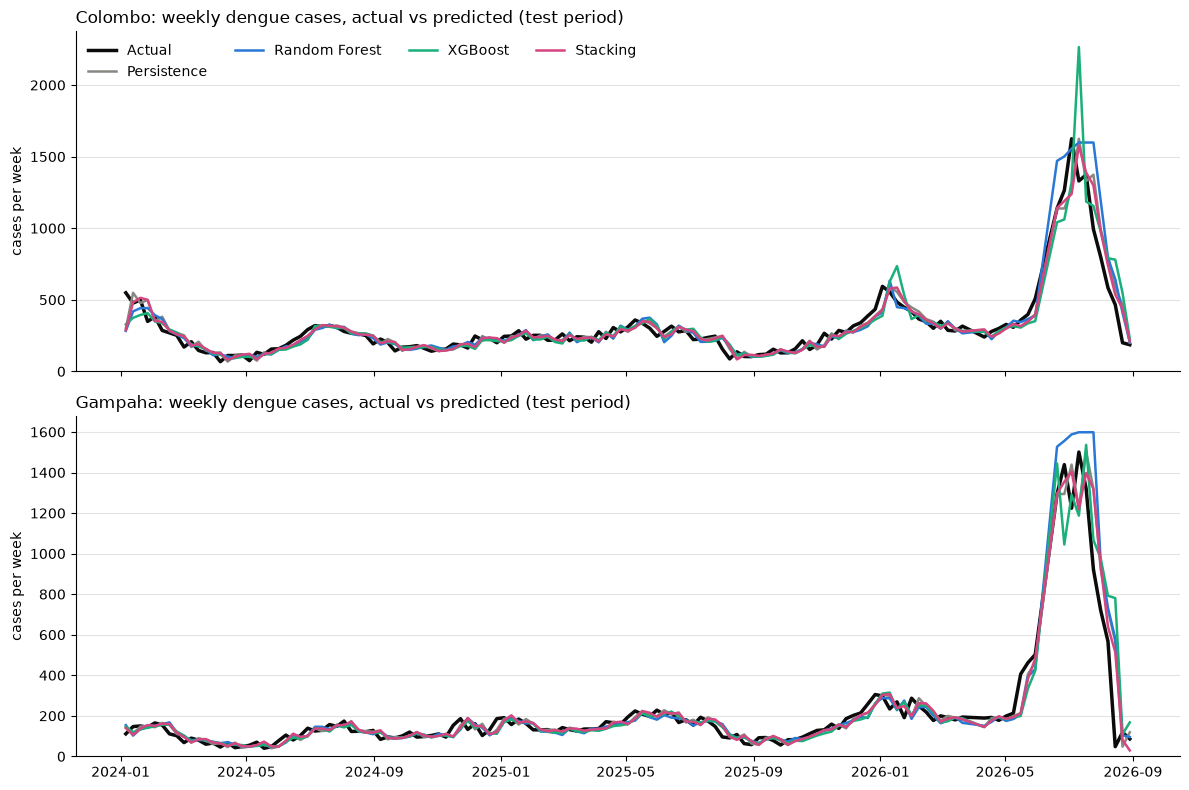

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, district in zip(axes, ["Colombo", "Gampaha"]):
    rows = (test["district"] == district).to_numpy()
    dates = test.loc[rows, "target_date"]
    ax.plot(dates, y_test[rows], color=INK, linewidth=2.5, label="Actual")
    for name in MODELS:
        ax.plot(dates, predictions[name][rows], color=COLORS[name], linewidth=1.8, label=name)
    ax.set_title(f"{district}: weekly dengue cases, actual vs predicted (test period)", loc="left")
    ax.set_ylabel("cases per week")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color=GRID)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, ncol=4)
plt.tight_layout()
plt.show()

### 6.2 Predicted vs actual, all test rows

Each dot is one district-week. Dots on the dashed diagonal are perfect predictions; dots **above** it are overestimates. Both axes use a log-like (symlog) scale so small and large districts are visible.

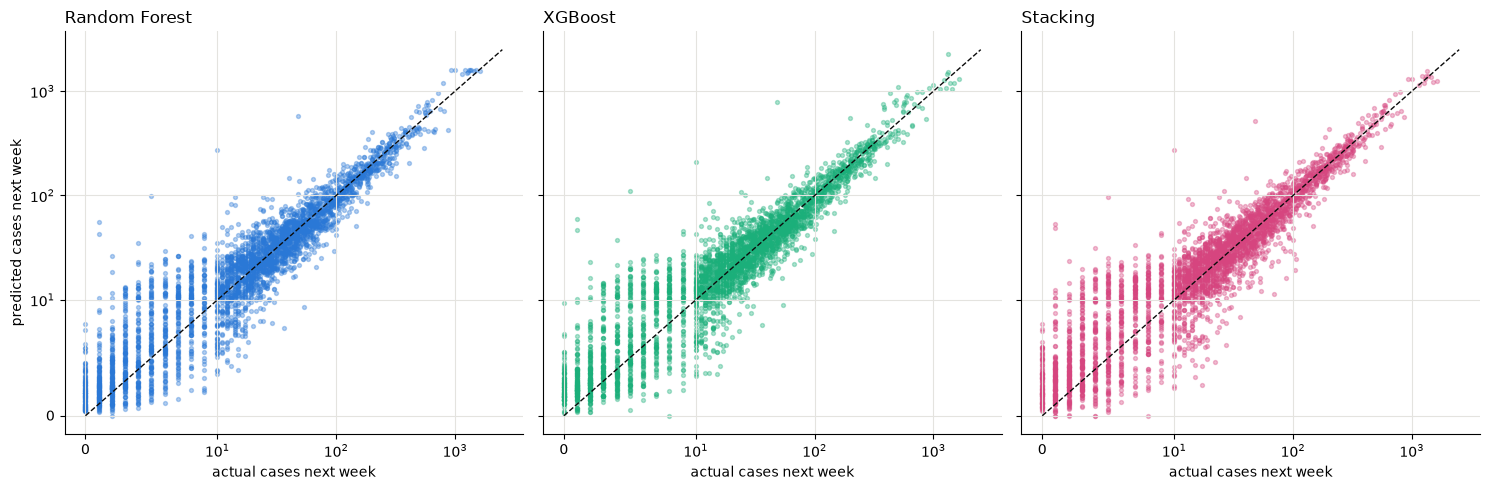

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, name in zip(axes, ENSEMBLES):
    ax.scatter(y_test, predictions[name], s=8, alpha=0.35, color=COLORS[name])
    ax.plot([0, 2500], [0, 2500], color=INK, linewidth=1, linestyle="--")
    ax.set_xscale("symlog", linthresh=10)
    ax.set_yscale("symlog", linthresh=10)
    ax.set_title(name, loc="left")
    ax.set_xlabel("actual cases next week")
    ax.grid(color=GRID)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("predicted cases next week")
plt.tight_layout()
plt.show()

## 7. Sensitivity check: duplicated weeks

Notebook 02 found four pairs of weeks where **all 26 counts are identical** to the week before (`dup_week`); most likely the same report was copied twice. They were kept because it is not known which copy is real. Two pairs are in the test period (2025 weeks 7/8 and 2026 weeks 25/26).

For the test rows whose current week **and** target week are such a copy, the target equals the current week, so persistence gets an error of exactly 0, which is probably not a real forecast success.

**This check does not replace the official test results above.** It re-scores the same predictions without the rows whose current or target week is a flagged duplicate. The rule comes from the data-quality flag of notebook 02 and is applied to all models in the same way; no model or setting is changed.

In [20]:
cleaned = pd.read_csv(CLEANED_PATH, parse_dates=["start_date"])
dup_dates = set(cleaned.loc[cleaned["dup_week"], "start_date"])

touches_dup = (test["start_date"].isin(dup_dates) | test["target_date"].isin(dup_dates)).to_numpy()
copied_target = (test["start_date"].isin(dup_dates) & test["target_date"].isin(dup_dates)).to_numpy()

print("test rows that use a duplicated week:", touches_dup.sum())
print("of which the target is a copy of the current week:", copied_target.sum(),
      "| persistence error on them:", np.abs(predictions["Persistence"][copied_target] - y_test[copied_target]).sum())

sensitivity = score_table(~touches_dup)
sensitivity.round(2)

test rows that use a duplicated week: 130
of which the target is a copy of the current week: 52 | persistence error on them: 0.0


,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.54,29.24,0.00,0.00
Random Forest,12.04,31.51,-3.97,7.76
XGBoost,12.81,38.11,2.12,30.31
Stacking,12.09,27.16,-3.60,-7.11


**What the sensitivity check shows**

- 130 test rows use a duplicated week; in 52 of them the target is an exact copy of the current week, so persistence is "perfect" on them.
- Without these rows, **Random Forest's MAE advantage over persistence grows from -0.8% to -4.0%**, and its MAE (12.04) becomes very slightly lower than Stacking's (12.09, -3.6%). XGBoost is still worse than persistence (+2.1%).
- **On RMSE, Stacking stays clearly best** (-7.1% vs persistence), while both tree ensembles remain worse than persistence.
- The duplicated weeks therefore make persistence look somewhat better than it is, and they decide whether Random Forest or Stacking has the lower MAE, but they **do not change the main conclusions**: Random Forest is ahead of XGBoost, and Stacking is the only ensemble with a clearly lower RMSE than persistence. The official test results in section 4 stay as they are.

## 8. Feature importance

Two kinds of importance are shown:

1. **Built-in importance** (computed from the training data):
   - Random Forest: **impurity-based** importance (how much each feature's splits reduce the squared error, averaged over the trees).
   - XGBoost: **gain** (average error reduction of the splits that use the feature).
2. **Permutation importance** (computed on the test set): shuffle one feature's values, so it no longer carries information, and measure how much the test MAE gets worse. Repeated 5 times per feature and averaged. For **Stacking** the shuffled feature goes into all three base models, then through the meta-model. Stacking has no built-in importance over the 11 features (its meta-model only sees the three base predictions; see notebook 07, section 9).

**Cautions**
- Importance shows what the model **uses**, not what **causes** dengue cases.
- The lag and moving-average features are strongly correlated. Correlated features **share** the importance, so one can look unimportant only because another carries the same information.
- Impurity and gain importance are measured on training data and favour features with many distinct values; permutation importance on unseen data is usually more reliable.
- Built-in importances of the two models are measured on different scales and are not directly comparable; compare the **ranking**.

In [21]:
xgb_gain = pd.Series(final_xgb.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0)

builtin = pd.DataFrame({
    "Random Forest (impurity)": final_rf.feature_importances_,
    "XGBoost (gain)": xgb_gain / xgb_gain.sum(),
}, index=FEATURES)

rng = np.random.default_rng(RANDOM_STATE)
permutation = {}
for name in ENSEMBLES:
    base_mae = mean_absolute_error(y_test, predictions[name])
    increase = {}
    for feature in FEATURES:
        repeats = []
        for _ in range(5):
            X_shuffled = X_test.copy()
            X_shuffled[feature] = rng.permutation(X_shuffled[feature].to_numpy())
            repeats.append(mean_absolute_error(y_test, predict_with(name, X_shuffled)) - base_mae)
        increase[feature] = np.mean(repeats)
    permutation[f"{name} (test MAE increase)"] = increase

importance = builtin.join(pd.DataFrame(permutation)).sort_values("Random Forest (impurity)", ascending=False)
importance.round(3)

,Random Forest (impurity),XGBoost (gain),Random Forest (test MAE increase),XGBoost (test MAE increase),Stacking (test MAE increase)
current_week_cases,0.905,0.672,39.460,29.557,33.090
moving_average_4_weeks,0.055,0.068,9.804,6.916,5.706
previous_week_cases,0.012,0.117,1.168,6.509,20.576
moving_average_8_weeks,0.006,0.014,0.582,1.143,1.404
seasonal_week_cos,0.006,0.066,0.108,0.090,-0.031
seasonal_week_sin,0.004,0.003,0.209,0.186,0.002
weekly_case_change,0.003,0.012,0.059,-0.095,0.788
previous_3_weeks_cases,0.003,0.024,0.417,0.496,4.283
previous_2_weeks_cases,0.003,0.003,0.225,0.066,3.433
seasonal_cases_previous_52_weeks,0.003,0.004,0.171,0.164,0.070


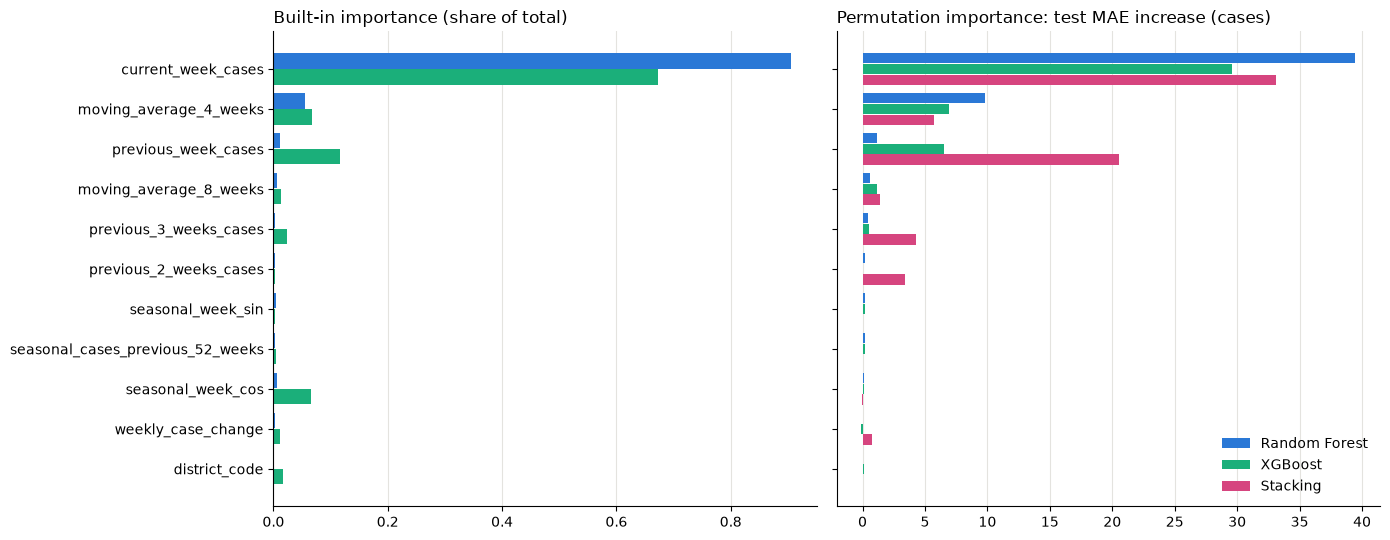

In [22]:
order = importance.sort_values("Random Forest (test MAE increase)").index
y = np.arange(len(order))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
ax = axes[0]
ax.barh(y + 0.2, importance.loc[order, "Random Forest (impurity)"], height=0.38, color=COLORS["Random Forest"], label="Random Forest")
ax.barh(y - 0.2, importance.loc[order, "XGBoost (gain)"], height=0.38, color=COLORS["XGBoost"], label="XGBoost")
ax.set_title("Built-in importance (share of total)", loc="left")
ax = axes[1]
for offset, name in zip([0.27, 0, -0.27], ENSEMBLES):
    ax.barh(y + offset, importance.loc[order, f"{name} (test MAE increase)"], height=0.26, color=COLORS[name], label=name)
ax.set_title("Permutation importance: test MAE increase (cases)", loc="left")
for ax in axes:
    ax.grid(axis="x", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(y, order)
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**What the importance shows**

- All three ensembles depend mostly on **`current_week_cases`**, then on the recent weeks. In other words, they have largely learned a smoothed version of the persistence rule, which explains why they are so close to it.
- **XGBoost relies more on the previous week** than the Random Forest (permutation: +6.5 cases MAE when shuffled, Random Forest: +1.2) and on the seasonal position.
- **Stacking relies much more on the previous weeks** (previous week: +20.6, two and three weeks ago: +3.4 and +4.3), because its meta-model follows Linear Regression, which weights last week heavily and subtracts a little for the weeks before (notebook 04). It uses the "shape" of the recent curve, not just the current level.
- For XGBoost, shuffling **`weekly_case_change`** makes the test MAE slightly *better* (-0.1). The feature does not help XGBoost on the test years, which is consistent with the overshoot found in section 5.5.
- The 52-week seasonal lag and the district code contribute very little to any model.

## 9. Save the results

- **Results:** `models/08_final_test_results.json`, used by the dashboard.
- **Predictions:** `models/08_test_predictions.csv`, every test row with the actual value and the four predictions, so the results can be checked without retraining.

The models themselves were already saved in notebooks 05, 06 and 07.

In [23]:
saved_predictions = test[["district", "start_date", "target_date", "current_week_cases", TARGET]].rename(
    columns={TARGET: "actual_cases_next", "current_week_cases": "persistence_pred"})
saved_predictions["random_forest_pred"] = predictions["Random Forest"]
saved_predictions["xgboost_pred"] = predictions["XGBoost"]
saved_predictions["stacking_pred"] = predictions["Stacking"]
saved_predictions.to_csv(PREDICTIONS_PATH, index=False, date_format="%Y-%m-%d")
print("saved", PREDICTIONS_PATH, saved_predictions.shape)


def to_dict(table):
    return {str(k): {c: float(v) for c, v in row.items()} for k, row in table.round(3).to_dict(orient="index").items()}


results = {
    "created_by": "notebooks analysis/08_final_comparison.ipynb",
    "note": "Comparison of the final Random Forest (notebook 05, bagging), XGBoost (notebook 06, boosting) and Stacking (notebook 07) models.",
    "train_rows": int(len(train)),
    "test_rows": int(len(test)),
    "train_target_weeks": [str(train["target_date"].min().date()), str(train["target_date"].max().date())],
    "test_target_weeks": [str(test["target_date"].min().date()), str(test["target_date"].max().date())],
    "random_forest_params": {**RF_PARAMS, "random_state": RANDOM_STATE},
    "xgboost_params": {**XGB_PARAMS, "random_state": RANDOM_STATE},
    "stacking_meta_model": stack_info["meta_model"],
    "stacking_base_models": BASE_MODELS,
    "test_scores": to_dict(test_results),
    "test_scores_by_year": to_dict(by_year.drop(columns="rows")),
    "base_model_test_error_correlation": to_dict(base_errors.corr()),
    "sensitivity_without_duplicated_weeks": {"rows": int((~touches_dup).sum()), "scores": to_dict(sensitivity)},
    "feature_importance": to_dict(importance),
    "library_versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                         "pandas": pd.__version__, "numpy": np.__version__},
}
RESULTS_PATH.write_text(json.dumps(results, indent=2))
print("saved", RESULTS_PATH)

saved ..\models\08_test_predictions.csv (3508, 8)
saved ..\models\08_final_test_results.json


## 10. Summary

**Final test results** (target weeks 2024-01-06 to 2026-08-29, the same 3,508 district-weeks for every model; all models trained on target weeks 2007-2023 with settings chosen on 2023)

| Model | Notebook | Settings | Test MAE | Test RMSE | MAE vs persistence | RMSE vs persistence |
|---|---|---|---|---|---|---|
| Persistence | - | none | 12.63 | 29.93 | - | - |
| Random Forest (bagging) | 05 | 200 trees, `min_samples_leaf=10` | 12.53 | 33.63 | -0.8% | +12.4% |
| XGBoost (boosting) | 06 | 400 rounds, `max_depth=2`, `learning_rate=0.05` | 13.22 | 39.19 | +4.6% | +30.9% |
| Stacking | 07 | RF + XGBoost + Linear Regression, linear meta-model (`positive=True`) | **12.18** | **27.72** | **-3.6%** | **-7.4%** |

| Test year | Persistence MAE | Random Forest MAE | XGBoost MAE | Stacking MAE |
|---|---|---|---|---|
| 2024 | 10.45 | 9.53 | **9.47** | 10.24 |
| 2025 | 8.68 | 8.31 | **8.27** | 8.63 |
| 2026 (to August) | 22.93 | 24.66 | 27.82 | **21.42** |

**Conclusions**
1. **Stacking had the best overall test scores** and is the only ensemble that beats persistence on both MAE and RMSE. Its advantage comes from the 2026 outbreak and the largest districts; in the moderate years 2024-2025 the tree ensembles were slightly better.
2. **Bagging (Random Forest) generalised better than boosting (XGBoost):** lower MAE and RMSE overall, a much smaller RMSE in the 2026 outbreak, and a lower MAE in 18 of 26 reporting areas. XGBoost's small win on the 2023 validation year did not carry over.
3. **Why stacking won is important:** the Random Forest and XGBoost made almost the same errors in the years the meta-model learned from (correlation 0.98), so combining them added nothing. The meta-model put nearly all its weight on the **Linear Regression** base model, which handled outbreaks better because it is not limited to past values. Linear Regression on its own scored even slightly better (test MAE 11.90, RMSE 26.95; notebook 07).
4. **XGBoost's poor test score comes from outbreak peaks**: it learned from a few extreme 2017 weeks that a large jump at a high level means an even higher next week, and it overestimated the 2026 peak badly.
5. The duplicated weeks slightly favour persistence; without them Random Forest's and Stacking's MAE advantages are both about 4%, but the conclusions do not change.
6. These are honest results: the settings were fixed before the test set was used, all models were scored on identical rows, and nothing was changed after seeing the test scores.

**Saved:** `models/08_final_test_results.json`, `models/08_test_predictions.csv`.

**Limitations:** a single test period (2024-2026) dominated by one large outbreak; no statistical significance test of the differences; the most recent 2026 weeks may be incomplete; only past case counts are used as features (no rainfall, temperature or mobility data).